In [3]:

%pip install scipy

Note: you may need to restart the kernel to use updated packages.


In [3]:
import pandas as pd
import numpy as np
from scipy.stats import binom, poisson
import matplotlib.pyplot as plt

df = pd.read_csv('sales_electroprima3.csv')
df['date'] = pd.to_datetime(df['date'])
df.head()
df.shape

(2200, 14)

In [4]:
valid = df['satisfaction_rating'].dropna()
p_rating5 = (valid == 5).mean()
print('Proportion of rating 5 (p):', round(p_rating5, 4))

Proportion of rating 5 (p): 0.3419


In [5]:
n = 10
k = 3
p_exact3 = binom.pmf(k, n, p_rating5)
print(f'P(X = {k}) = {p_exact3:.4f}')

P(X = 3) = 0.2564


In [6]:
p_atmost3 = binom.cdf(3, n, p_rating5)
print(f'P(X <= 3) = {p_atmost3:.4f}')

P(X <= 3) = 0.5359


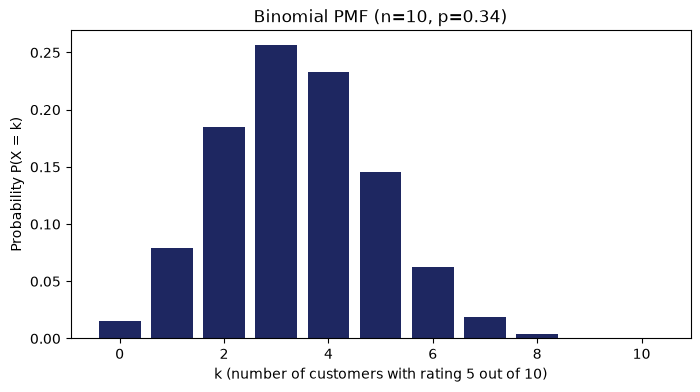

In [7]:
k_vals = np.arange(0, n + 1)
pmf_vals = binom.pmf(k_vals, n, p_rating5)

plt.figure(figsize=(8, 4))
plt.bar(k_vals, pmf_vals, color='#1E2761')
plt.xlabel('k (number of customers with rating 5 out of 10)')
plt.ylabel('Probability P(X = k)')
plt.title('Binomial PMF (n=10, p=' + str(round(p_rating5,2)) + ')')
plt.show()

In [8]:
complaints = df[df['satisfaction_rating'] <= 2]
daily = complaints.groupby('date').size()
date_range = pd.date_range(df['date'].min(), df['date'].max())
daily = daily.reindex(date_range, fill_value=0)
lam = daily.mean()
print('Lambda (average complaints/day):', round(lam, 4))

Lambda (average complaints/day): 1.0497


In [9]:
p_gt5 = poisson.sf(5, mu=lam)
print(f'P(X > 5) = {p_gt5:.6f}')

P(X > 5) = 0.000762


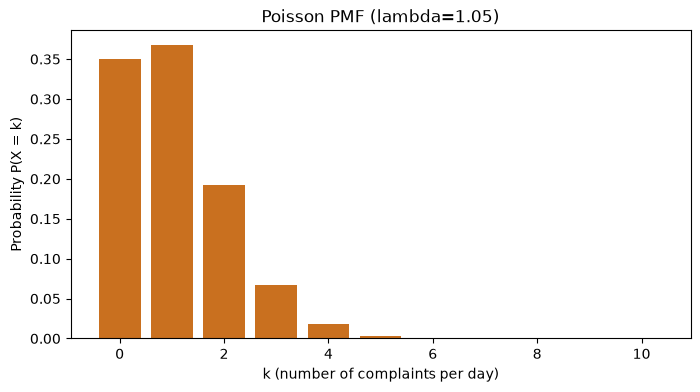

In [10]:
k_vals2 = np.arange(0, 11)
pmf_poisson = poisson.pmf(k_vals2, mu=lam)

plt.figure(figsize=(8, 4))
plt.bar(k_vals2, pmf_poisson, color='#C9701F')
plt.xlabel('k (number of complaints per day)')
plt.ylabel('Probability P(X = k)')
plt.title('Poisson PMF (lambda=' + str(round(lam,2)) + ')')
plt.show()

In [15]:
col_branch = [c for c in df.columns if 'branch' in c or 'cabang' in c][0]
valid_malang = df[df[col_branch] == 'Malang']['satisfaction_rating'].dropna()
p_malang = (valid_malang == 5).mean()
p_exact3_malang = binom.pmf(3, 10, p_malang)
p_atmost3_malang = binom.cdf(3, 10, p_malang)
print(f"Malang - p: {p_malang:.4f} | P(X=3): {p_exact3_malang:.4f} | P(X<=3): {p_atmost3_malang:.4f}")

Malang - p: 0.3498 | P(X=3): 0.2524 | P(X<=3): 0.5145


In [14]:
col_cat = [c for c in df.columns if 'cat' in c or 'kategori' in c or 'product' in c][0]
valid_smart = df[df[col_cat] == 'Smartphone']['satisfaction_rating'].dropna()
p_smart = (valid_smart == 5).mean()
p_exact5_smart = binom.pmf(5, 15, p_smart)
print(f"Smartphone - p: {p_smart:.4f} | P(X=5, n=15): {p_exact5_smart:.4f}")

Smartphone - p: 0.3370 | P(X=5, n=15): 0.2142


In [16]:
lam_double = 2 * lam
p_gt5_double = poisson.sf(5, mu=lam_double)
ratio = p_gt5_double / p_gt5 if p_gt5 > 0 else 0
print(f"Lambda Awal: {lam:.4f} (P>5: {p_gt5:.6f})")
print(f"Lambda Ganda: {lam_double:.4f} (P>5: {p_gt5_double:.6f})")
print(f"Faktor Kenaikan Probabilitas: {ratio:.2f}x lipat")

Lambda Awal: 1.0497 (P>5: 0.000762)
Lambda Ganda: 2.0994 (P>5: 0.020426)
Faktor Kenaikan Probabilitas: 26.79x lipat
